1. Imports, sementes e carregamento estratificado

In [2]:
import sys
from pathlib import Path
import importlib
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT_DIR = Path("..").resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import src.train
import src.models
importlib.reload(src.train)
importlib.reload(src.models)

from src.train import set_seed, prepare_dataset, treinar_modelo
from src.models import MLP

RANDOM_STATE = 42
SEEDS = [42, 100, 202, 303, 404]
BATCH_SIZE = 256

set_seed(RANDOM_STATE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Rodando em:", device)

clf_data = prepare_dataset(
    csv_path=str(ROOT_DIR / "data" / "processed" / "dataset_classification.csv"),
    task="classification",
    target_col="TARGET",
    random_state=RANDOM_STATE,
    batch_size=BATCH_SIZE,
)

for nome in ["train", "val", "test"]:
    X_part = clf_data["scaled_splits"][f"X_{nome}"]
    y_part = clf_data["scaled_splits"][f"y_{nome}"]
    prop_1 = np.mean(y_part == 1) * 100
    print(f"{nome:5s} -> X: {X_part.shape}, y: {y_part.shape} | classe 1: {prop_1:.2f}%")

Rodando em: cpu
train -> X: (160000, 5), y: (160000,) | classe 1: 20.07%
val   -> X: (40000, 5), y: (40000,) | classe 1: 20.08%
test  -> X: (50000, 5), y: (50000,) | classe 1: 20.07%


2. Treinamento Baseline de Classificação (BCEWithLogitsLoss)

In [3]:
set_seed(SEEDS[0])

modelo_clf_base = MLP(
    in_features=clf_data["n_features"],  # 5 features
    out_features=1,                      # 1 logit (sem sigmoide na saída)
    hidden_units=(64, 32),
    activation="ReLU",
    dropout=0.0,
).to(device)

loss_fn_clf = torch.nn.BCEWithLogitsLoss()
otimizador_clf = torch.optim.Adam(modelo_clf_base.parameters(), lr=1e-3)

res_clf = treinar_modelo(
    modelo=modelo_clf_base,
    dl_treino=clf_data["loaders"]["train"],
    dl_val=clf_data["loaders"]["val"],
    loss_fn=loss_fn_clf,
    otimizador=otimizador_clf,
    device=device,
    n_epocas=100,
    paciencia=15,
)

print(f"Épocas rodadas: {res_clf['epocas_rodadas']} | Melhor época: {res_clf['melhor_epoca']}")
print(f"Melhor perda Val (BCEWithLogitsLoss): {res_clf['melhor_val']:.6f}")
print(f"Tempo total: {res_clf['tempo_s']:.2f}s")

Épocas rodadas: 100 | Melhor época: 97
Melhor perda Val (BCEWithLogitsLoss): 0.119006
Tempo total: 158.92s


3. Curva de Perda e Generalização (Classificação Baseline)

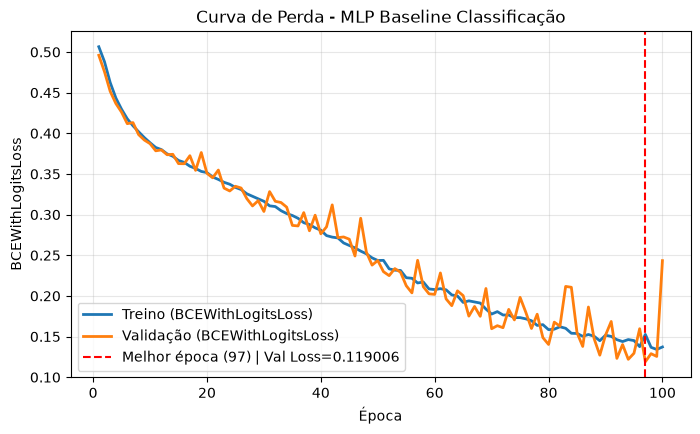

Gap (Val - Treino) na melhor época (97): -0.033639
Gap (Val - Treino) na última época (100): 0.106179


In [4]:
hist_tr_clf = res_clf["historico"]["treino"]
hist_va_clf = res_clf["historico"]["val"]
epocas_clf = range(1, len(hist_tr_clf) + 1)
melhor_ep_clf = res_clf["melhor_epoca"]
melhor_v_clf = res_clf["melhor_val"]

fig_dir = ROOT_DIR / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 4.5))
plt.plot(epocas_clf, hist_tr_clf, label="Treino (BCEWithLogitsLoss)", linewidth=2)
plt.plot(epocas_clf, hist_va_clf, label="Validação (BCEWithLogitsLoss)", linewidth=2)
plt.axvline(
    melhor_ep_clf,
    color="red",
    linestyle="--",
    label=f"Melhor época ({melhor_ep_clf}) | Val Loss={melhor_v_clf:.6f}",
)
plt.title("Curva de Perda - MLP Baseline Classificação")
plt.xlabel("Época")
plt.ylabel("BCEWithLogitsLoss")
plt.legend()
plt.grid(True, alpha=0.3)

caminho_fig_clf = fig_dir / "mlp_clf_baseline_curva_perda.png"
plt.savefig(caminho_fig_clf, dpi=150, bbox_inches="tight")
plt.show()

gap_melhor_clf = hist_va_clf[melhor_ep_clf - 1] - hist_tr_clf[melhor_ep_clf - 1]
gap_final_clf = hist_va_clf[-1] - hist_tr_clf[-1]
print(f"Gap (Val - Treino) na melhor época ({melhor_ep_clf}): {gap_melhor_clf:.6f}")
print(f"Gap (Val - Treino) na última época ({len(hist_va_clf)}): {gap_final_clf:.6f}")

4. Probabilidades e Métricas na Validação (limiar 0.5)

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)

modelo_clf_base.eval()
probs_val_list = []

with torch.no_grad():
    for xb, _ in clf_data["loaders"]["val"]:
        xb = xb.to(device)
        logits = modelo_clf_base(xb)
        probs = torch.sigmoid(logits).cpu().numpy().ravel()
        probs_val_list.append(probs)

y_val_prob = np.concatenate(probs_val_list)
y_val_true = clf_data["raw_splits"]["y_val"]
y_val_pred = (y_val_prob >= 0.5).astype(int)

print("=== Métricas na Validação (Limiar = 0.50) ===")
print(f"Accuracy  : {accuracy_score(y_val_true, y_val_pred):.4f}")
print(f"Precision : {precision_score(y_val_true, y_val_pred):.4f}")
print(f"Recall    : {recall_score(y_val_true, y_val_pred):.4f}")
print(f"F1-score  : {f1_score(y_val_true, y_val_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_val_true, y_val_prob):.4f}")
print(f"PR-AUC    : {average_precision_score(y_val_true, y_val_prob):.4f}")
print("\nMatriz de confusão (linhas = real, colunas = previsto):")
print(confusion_matrix(y_val_true, y_val_pred))

=== Métricas na Validação (Limiar = 0.50) ===
Accuracy  : 0.9515
Precision : 0.9974
Recall    : 0.7603
F1-score  : 0.8628
ROC-AUC   : 0.9897
PR-AUC    : 0.9817

Matriz de confusão (linhas = real, colunas = previsto):
[[31954    16]
 [ 1925  6105]]
